# ERCOT Hourly Dispatch — Generators → Zones (no storage, no emission cost)

**Question:** what is the cheapest way to meet each ERCOT weather zone's hourly demand during **August 4–10, 2025** using the existing generator fleet?

**Simplifications for this first version**
- No battery storage (no charging, discharging or state of charge).
- No emission cost (β = 0). Emissions are still *reported*, not priced.
- No zone-to-zone transfers or line limits: every generator can supply every zone, and distance only adds a cost.

**Approach**
1. Load the cleaned CSVs and check they line up (IDs, hours, units).
2. Turn them into model parameters: costs, distances, demand, hourly capacity.
3. Write the linear program in JuMP and solve it with Gurobi.
4. Check the solution (status, demand met, capacity respected) and verify the cost independently.
5. Look at the results: cost, generation mix, hourly dispatch, zonal prices, which plants serve which zone.

In [1]:
using CSV, DataFrames, JuMP, Gurobi, Plots, Printf, Statistics, TOML

# --- display helpers: clean tables and readable numbers ---------------------------------
"Number with thousands separators, e.g. 5966875.9 → \"5,966,876\" (d = decimals)."
commas(x; d = 0) = (s = @sprintf("%.*f", d, x); m = match(r"^(-?)(\d+)(\.\d+)?$", s);
                    m[1] * replace(m[2], r"(?<=\d)(?=(\d{3})+$)" => ",") * something(m[3], ""))
"Show a DataFrame as a plain HTML table (no type row, no row numbers, no size line)."
table(df) = display(HTML(sprint(io -> show(io, MIME("text/html"), df; eltypes = false, summary = false,
                                            show_row_number = false))))
"Short labels for the two long gas names."
SHORT = Dict("Natural Gas - Combined Cycle" => "Gas CC", "Natural Gas - Non-Combined Cycle" => "Gas non-CC")
short(s) = get(SHORT, s, s)

short (generic function with 1 method)

## 1. Inputs

All files are in `Data Processing/data/cleaned_data/` (tracked in git as `Data/`, so both spellings are accepted).

| File | Used for |
|---|---|
| `generators_2025-08-04.csv` | 679 generator groups: `id`, `Energy Source`, nameplate & summer capacity |
| `native_load_2025_cleaned.csv` | hourly demand for the 8 zones (the `ERCOT` total is only a cross-check) |
| `renewable_capacity_factors.csv` | hourly solar and wind capacity factors |
| `Fuel_costs.csv` | marginal cost per technology ($/MWh) |
| `distance_generator_zone.csv` | generator → zone distance (km) |
| `emission_costs.csv` | emission factor per technology (reported only) |
| `config.toml` | α, the distance cost ($/MWh per km) |

In [2]:
REPO = normpath(joinpath(@__DIR__, ".."))
DATA = first(filter(isdir, [joinpath(REPO, "Data Processing", d, "cleaned_data") for d in ("data", "Data")]))
OUT  = joinpath(@__DIR__, "output", "model_no_storage_no_emission"); mkpath(OUT)

ZONES = ["COAST", "EAST", "FWEST", "NORTH", "NCENT", "SOUTH", "SCENT", "WEST"]
Δt    = 1.0                                                               # hours per period
α     = Float64(TOML.parsefile(joinpath(REPO, "config.toml"))["transmission"]["alpha"])   # $/MWh per km
β     = 0.0                                                               # emission cost: off

readcsv(f; kw...) = CSV.read(joinpath(DATA, f), DataFrame; stripwhitespace = true, kw...)
gens  = readcsv("generators_2025-08-04.csv"; types = Dict(:id => String))
load  = readcsv("native_load_2025_cleaned.csv"; types = Dict(Symbol("Hour Ending") => String))
cf    = readcsv("renewable_capacity_factors.csv"; types = Dict(Symbol("Hour Ending") => String))
fuel  = readcsv("Fuel_costs.csv")
emis  = readcsv("emission_costs.csv")
dist  = readcsv("distance_generator_zone.csv"; types = Dict(:generator_id => String))
rename!(fuel, strip.(replace.(names(fuel), '﻿' => "")))

println("Data folder:  ", relpath(DATA, REPO))
println("α (distance): $α \$/MWh per km   (from config.toml)")
println("β (emission): $β")
println("\nFirst rows of the generator file:")
table(first(gens[:, ["id", "Energy Source", "Nameplate Capacity (MW)", "Summer Capacity (MW)", "Generator Count"]], 5))

Data folder:  Data Processing/data/cleaned_data


α (distance): 0.001223 $/MWh per km   (from config.toml)
β (emission): 0.0

First rows of the generator file:


id,Energy Source,Nameplate Capacity (MW),Summer Capacity (MW),Generator Count
NGCC_3559,Natural Gas - Combined Cycle,75.0,62.0,2
NGCT_3559,Natural Gas - Non-Combined Cycle,61.0,45.0,1
NGCT_64777,Natural Gas - Non-Combined Cycle,1.2,1.2,3
SOLAR_65661,Solar,180.0,180.0,2
WIND_59712,Wind,95.3,95.3,1


### Data checks
Everything must line up before we trust the model. Any failure stops the notebook here.

In [3]:
hours = String.(load[!, "Hour Ending"])
checks = [
    (nrow(gens) == 679 && allunique(gens.id),                         "679 generators, unique ids"),
    (length(hours) == 168 && allunique(hours),                        "168 unique hours"),
    (String.(cf[!, "Hour Ending"]) == hours,                          "capacity-factor hours = load hours, same order (incl. 24:00)"),
    (all(z -> z in names(load), ZONES),                               "load file has all 8 zones"),
    (maximum(abs.(sum(Matrix(load[!, ZONES]); dims = 2) .- load.ERCOT)) <= 0.05, "zones add up to the ERCOT total (±0.05 MW)"),
    (all(x -> 0 <= x <= 1, [cf.solar_capacity_factor; cf.wind_capacity_factor]), "capacity factors within [0, 1]"),
    (Set(dist.generator_id) == Set(gens.id) && allunique(dist.generator_id),     "distance ids = generator ids"),
    (Set(gens[!, "Energy Source"]) ⊆ Set(fuel.energy_source),          "every technology has a fuel cost"),
    (Set(gens[!, "Energy Source"]) ⊆ Set(emis.energy_source),          "every technology has an emission factor"),
    (all(>=(0), Matrix(dist[!, ZONES])) && all(>=(0), Matrix(load[!, ZONES])),   "distances and demand ≥ 0"),
]
table(DataFrame(check = last.(checks), result = [ok ? "✔ pass" : "✘ FAIL" for ok in first.(checks)]))
all(first.(checks)) || error("A data check failed — see the table above.")

check,result
"679 generators, unique ids",✔ pass
168 unique hours,✔ pass
"capacity-factor hours = load hours, same order (incl. 24:00)",✔ pass
load file has all 8 zones,✔ pass
zones add up to the ERCOT total (±0.05 MW),✔ pass
"capacity factors within [0, 1]",✔ pass
distance ids = generator ids,✔ pass
every technology has a fuel cost,✔ pass
every technology has an emission factor,✔ pass
distances and demand ≥ 0,✔ pass


true

## 2. Sets and parameters

| Symbol | Meaning | Source |
|---|---|---|
| $I$ | generators (679) | `id` |
| $J$ | zones (8) | zone columns |
| $T$ | hours (168) | `Hour Ending` |
| $c_i$ | marginal cost, $/MWh | `Fuel_costs.csv` by `Energy Source` |
| $d_{ij}$ | distance generator → zone, km | `distance_generator_zone.csv` |
| $D_{jt}$ | demand, MWh | load × Δt |
| $\bar g_{it}$ | max output in hour t, MWh | see below |

**Hourly capacity** $\bar g_{it}$:
- Coal, gas, nuclear, hydro: `Summer Capacity (MW)` × Δt (the week is in August).
- Solar: `Nameplate Capacity (MW)` × solar capacity factor$_t$ × Δt.
- Wind: `Nameplate Capacity (MW)` × wind capacity factor$_t$ × Δt.

In [4]:
ids  = gens.id
tech = String.(gens[!, "Energy Source"])
I, J, T = length(ids), length(ZONES), length(hours)

cost_of = Dict(r.energy_source => Float64(r.marginal_cost_usd_per_mwh) for r in eachrow(fuel))
emis_of = Dict(r.energy_source => Float64(r.value) for r in eachrow(emis))
c = [cost_of[s] for s in tech]                                    # $/MWh
e = [emis_of[s] for s in tech]                                    # factor units / MWh (unit unconfirmed)

row = Dict(g => k for (k, g) in enumerate(dist.generator_id))
d = [Float64(dist[row[g], z]) for g in ids, z in ZONES]           # I × J, km

D = Matrix{Float64}(load[!, ZONES])' .* Δt                        # J × T, MWh

nameplate, summer = Float64.(gens[!, "Nameplate Capacity (MW)"]), Float64.(gens[!, "Summer Capacity (MW)"])
cap = zeros(I, T)                                                 # I × T, MWh
for i in 1:I, t in 1:T
    cap[i, t] = tech[i] == "Solar" ? nameplate[i] * cf.solar_capacity_factor[t] * Δt :
                tech[i] == "Wind"  ? nameplate[i] * cf.wind_capacity_factor[t]  * Δt :
                                     summer[i] * Δt
end

# Technologies in merit order (cheapest first)
TECHS = sort(unique(tech); by = s -> (cost_of[s], s))
table(DataFrame("Technology" => short.(TECHS),
                "Cost (\$/MWh)" => [@sprintf("%.2f", cost_of[s]) for s in TECHS],
                "Generators" => [count(==(s), tech) for s in TECHS],
                "Capacity used" => [s in ("Wind", "Solar") ? "nameplate × CF" : "summer" for s in TECHS],
                "Avg hourly capacity (GW)" => [@sprintf("%.1f", sum(cap[tech .== s, :]) / T / 1000) for s in TECHS]))

Technology,Cost ($/MWh),Generators,Capacity used,Avg hourly capacity (GW)
Solar,0.00,188,nameplate × CF,8.6
Wind,0.00,193,nameplate × CF,14.7
Nuclear,12.76,2,summer,5.0
Hydro,15.14,13,summer,0.5
Gas CC,22.83,60,summer,38.7
Coal,31.36,9,summer,12.7
Gas non-CC,33.88,214,summer,20.2


Before building anything: is there enough capacity in every hour? (If not, the model would be infeasible.)

In [5]:
avail, demand_tot = vec(sum(cap; dims = 1)), vec(sum(D; dims = 1))
margin = avail .- demand_tot
tight = argmin(margin)
println("Tightest hour:  ", hours[tight])
println("  available:    ", commas(avail[tight] / 1000; d = 1), " GW")
println("  demand:       ", commas(demand_tot[tight] / 1000; d = 1), " GW")
println("  spare:        ", commas(margin[tight] / 1000; d = 1), " GW  (", @sprintf("%.1f", 100 * margin[tight] / demand_tot[tight]), "% of demand)")
all(margin .>= 0) || error("Some hour has less capacity than demand — the model would be infeasible.")
println("\n✔ Every hour has enough total capacity.")

Tightest hour:  08/07/2025 21:00
  available:    

91.8 GW
  demand:       76.9 GW
  spare:        14.9 GW  (19.3% of demand)

✔ Every hour has enough total capacity.


## 3. Model

**Decision variable:** $x_{ijt} \ge 0$ = MWh sent from generator $i$ to zone $j$ in hour $t$.

$$
\min \; \sum_{i,j,t} \big(c_i + \alpha\, d_{ij}\big)\, x_{ijt} \;+\; \beta \sum_{i,j,t} e_i\, x_{ijt}
$$

subject to

$$
\begin{aligned}
\sum_{i} x_{ijt} &\ge D_{jt} && \forall j, t \quad \text{(meet each zone's demand)}\\
\sum_{j} x_{ijt} &\le \bar g_{it} && \forall i, t \quad \text{(generator's total output within its hourly capacity)}\\
x_{ijt} &\ge 0
\end{aligned}
$$

With β = 0 the emission term drops out. It is a continuous LP: 679 × 8 × 168 = 912,576 variables.

In [6]:
model = Model(Gurobi.Optimizer)
set_silent(model)

@variable(model, x[1:I, 1:J, 1:T] >= 0)

@constraint(model, demand[j in 1:J, t in 1:T],   sum(x[i, j, t] for i in 1:I) >= D[j, t])
@constraint(model, capacity[i in 1:I, t in 1:T], sum(x[i, j, t] for j in 1:J) <= cap[i, t])

@objective(model, Min, sum((c[i] + α * d[i, j] + β * e[i]) * x[i, j, t] for i in 1:I, j in 1:J, t in 1:T))

println("\nVariables:   ", commas(num_variables(model)))
println("Constraints: ", commas(num_constraints(model; count_variable_in_set_constraints = false)),
        "  (", commas(J * T), " demand + ", commas(I * T), " capacity)")

Set parameter Username
Set parameter LicenseID to value 2857569
Academic license - for non-commercial use only - expires 2027-08-26

Variables:   912,576


Constraints: 

115,416  (1,344 demand + 114,072 capacity)


In [7]:
optimize!(model)
ok = termination_status(model) == MOI.OPTIMAL && primal_status(model) == MOI.FEASIBLE_POINT
println(ok ? "✔ " : "✘ ", "Status: ", termination_status(model), " / ", primal_status(model))
@printf("  Solve time: %.1f s\n", solve_time(model))
ok || error("No optimal solution — stopping.")

✔ Status: 

OPTIMAL / FEASIBLE_POINT
  Solve time: 7.4 s


true

## 4. Check the solution

In [8]:
X        = value.(x)
gen      = dropdims(sum(X; dims = 2); dims = 2)      # I × T: each generator's total output
supplied = dropdims(sum(X; dims = 1); dims = 1)      # J × T: what each zone receives

gen_cost   = sum(c .* gen)
dist_cost  = α * sum(d[i, j] * X[i, j, t] for i in 1:I, j in 1:J, t in 1:T)
E          = sum(e .* gen)
objective  = objective_value(model)

tol = 1e-6
sol_checks = [
    ("Largest demand shortfall",   max(0, maximum(D .- supplied)),         "MWh"),
    ("Largest capacity violation", max(0, maximum(gen .- cap)),            "MWh"),
    ("Total oversupply",           sum(max.(supplied .- D, 0)),            "MWh"),
    ("Objective − recomputed cost", abs(objective - gen_cost - dist_cost - β * E), "\$"),
]
table(DataFrame("Check" => first.(sol_checks),
                "Value" => [@sprintf("%.1e %s", v, u) for (_, v, u) in sol_checks],
                "Result" => [v <= tol * max(1, abs(objective)) ? "✔ ≈ 0" : "✘ check" for (_, v, _) in sol_checks]))

Check,Value,Result
Largest demand shortfall,2.9e-11 MWh,✔ ≈ 0
Largest capacity violation,5.7e-14 MWh,✔ ≈ 0
Total oversupply,1.0e-09 MWh,✔ ≈ 0
Objective − recomputed cost,1.3e-06 $,✔ ≈ 0


**Independent check (merit order).** Ignoring distance, the cheapest way to meet total demand in each hour is to stack generators from cheapest to most expensive until demand is covered. That gives a lower bound on the generation cost. With α > 0 the model may pay slightly more in fuel to save on distance, so its generation cost should be equal to or just above this bound.

In [9]:
function merit_order_cost(c, cap, D)
    total, order = 0.0, sortperm(c)
    for t in axes(cap, 2)
        need = sum(D[:, t])
        for i in order
            q = min(need, cap[i, t]); total += c[i] * q; need -= q
            need <= 1e-9 && break
        end
    end
    total
end
mo = merit_order_cost(c, cap, D)
pct(a, b) = (v = 100 * (a - b) / b; abs(v) < 5e-5 ? 0.0 : v)     # treat rounding noise as 0
table(DataFrame("" => ["Merit-order generation cost (lower bound)", "Model generation cost", "Model total (incl. distance)"],
                "\$ million" => [@sprintf("%.3f", v / 1e6) for v in (mo, gen_cost, objective)],
                "vs. merit order" => ["—", @sprintf("%+.4f%%", pct(gen_cost, mo)), @sprintf("%+.2f%%", pct(objective, mo))]))
gen_cost >= mo - 1e-4 || error("Model generation cost is below the merit-order bound — something is wrong.")

,$ million,vs. merit order
Merit-order generation cost (lower bound),165.590,—
Model generation cost,165.590,+0.0000%
Model total (incl. distance),167.103,+0.91%


true

## 5. Results
### 5.1 Summary

In [10]:
table(DataFrame("Item" => ["Period", "Total demand", "Generation cost", "Distance cost (α × km × MWh)",
                           "Emission cost (β = 0)", "Total cost", "Average cost", "Emissions (not priced)"],
                "Value" => ["Aug 4–10, 2025 (168 h)",
                            commas(sum(D) / 1000; d = 1) * " GWh",
                            "\$" * @sprintf("%.2f", gen_cost / 1e6) * " M",
                            "\$" * @sprintf("%.2f", dist_cost / 1e6) * " M",
                            "\$0.00 M",
                            "\$" * @sprintf("%.2f", objective / 1e6) * " M",
                            "\$" * @sprintf("%.2f", objective / sum(D)) * " / MWh",
                            @sprintf("%.3f", E / 1e9) * " × 10⁹  (factor units × MWh; unit unconfirmed — if kg, ≈ " *
                                @sprintf("%.2f", E / 1e9) * " Mt CO₂)"]))

Item,Value
Period,"Aug 4–10, 2025 (168 h)"
Total demand,"11,350.2 GWh"
Generation cost,$165.59 M
Distance cost (α × km × MWh),$1.51 M
Emission cost (β = 0),$0.00 M
Total cost,$167.10 M
Average cost,$14.72 / MWh
Emissions (not priced),"2.914 × 10⁹ (factor units × MWh; unit unconfirmed — if kg, ≈ 2.91 Mt CO₂)"


### 5.2 Generation mix
Utilization = energy produced ÷ energy available over the week.

In [11]:
gwh(v) = sum(v) / 1000
table(DataFrame("Technology" => short.(TECHS),
                "Cost (\$/MWh)" => [@sprintf("%.2f", cost_of[s]) for s in TECHS],
                "Generation (GWh)" => [commas(gwh(gen[tech .== s, :]); d = 1) for s in TECHS],
                "Share" => [@sprintf("%.1f%%", 100 * sum(gen[tech .== s, :]) / sum(gen)) for s in TECHS],
                "Available (GWh)" => [commas(gwh(cap[tech .== s, :]); d = 1) for s in TECHS],
                "Utilization" => [@sprintf("%.0f%%", 100 * sum(gen[tech .== s, :]) / sum(cap[tech .== s, :])) for s in TECHS]))

Technology,Cost ($/MWh),Generation (GWh),Share,Available (GWh),Utilization
Solar,0.00,"1,444.1",12.7%,"1,444.1",100%
Wind,0.00,"2,462.0",21.7%,"2,462.0",100%
Nuclear,12.76,836.6,7.4%,836.6,100%
Hydro,15.14,88.9,0.8%,88.9,100%
Gas CC,22.83,"5,966.9",52.6%,"6,506.7",92%
Coal,31.36,535.2,4.7%,"2,129.9",25%
Gas non-CC,33.88,16.5,0.1%,"3,396.8",0%


### 5.3 Hourly dispatch
Stacked by technology, cheapest at the bottom. The dark line is total ERCOT demand.

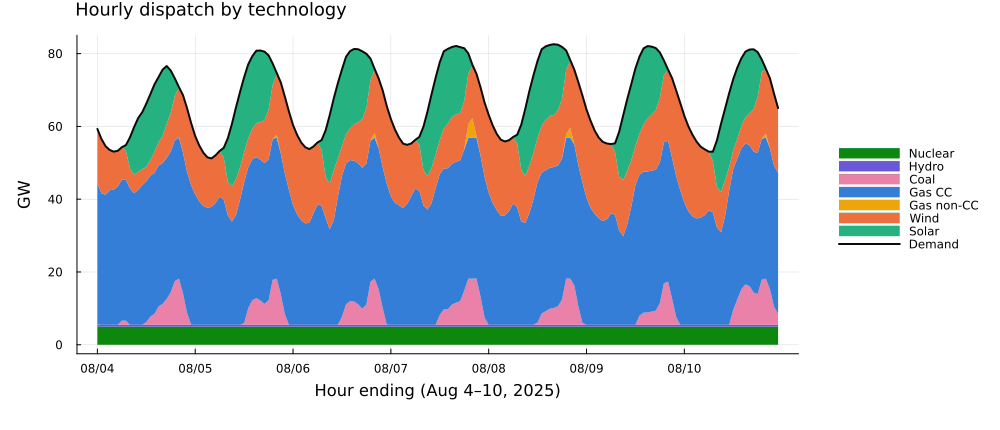

In [12]:
COLORS = Dict("Natural Gas - Combined Cycle" => "#2a78d6", "Wind" => "#eb6834", "Solar" => "#1baf7a",
              "Natural Gas - Non-Combined Cycle" => "#eda100", "Coal" => "#e87ba4", "Nuclear" => "#008300",
              "Hydro" => "#6250d6")
STACK = ["Nuclear", "Hydro", "Coal", "Natural Gas - Combined Cycle", "Natural Gas - Non-Combined Cycle", "Wind", "Solar"]
by_tech = hcat([vec(sum(gen[tech .== s, :]; dims = 1)) for s in STACK]...) ./ 1000      # T × techs, GW
day_ticks = (1:24:T, [hours[t][1:5] for t in 1:24:T])

gr()
p = areaplot(1:T, by_tech; label = permutedims(short.(STACK)),
             fillcolor = permutedims([COLORS[s] for s in STACK]), linewidth = 0, fillalpha = 0.95,
             size = (1000, 430), legend = :outerright, foreground_color_legend = nothing,
             xticks = day_ticks, xlabel = "Hour ending (Aug 4–10, 2025)", ylabel = "GW",
             title = "Hourly dispatch by technology", titlelocation = :left, titlefontsize = 12,
             gridalpha = 0.15, framestyle = :axes, left_margin = 5Plots.mm, bottom_margin = 5Plots.mm)
plot!(p, 1:T, demand_tot ./ 1000; color = "#0b0b0b", linewidth = 2, label = "Demand")
savefig(p, joinpath(OUT, "hourly_dispatch.png"))
p

### 5.4 What sets the price each hour?
The dual (shadow price) of a zone's demand constraint is the cost of serving **one more MWh** there in that hour — the zonal marginal price. Because every generator can reach every zone, prices differ across zones only by distance cost.

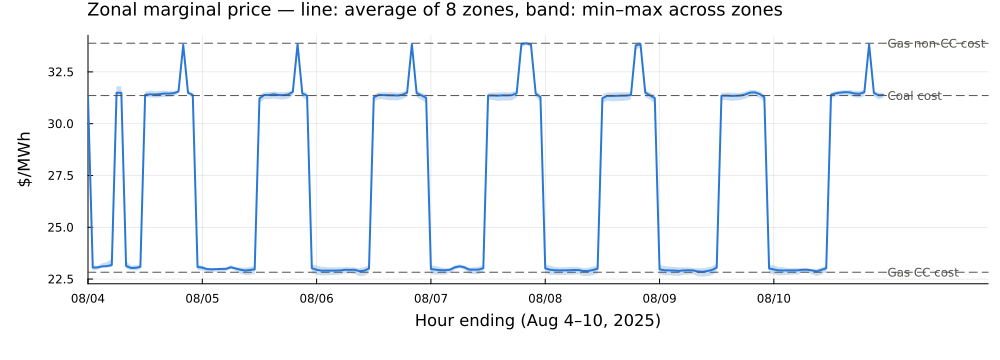

In [13]:
λ = [dual(demand[j, t]) for j in 1:J, t in 1:T]                   # $/MWh
λmin, λavg, λmax = vec(minimum(λ; dims = 1)), vec(mean(λ; dims = 1)), vec(maximum(λ; dims = 1))
p2 = plot(1:T, λavg; ribbon = (λavg .- λmin, λmax .- λavg), fillalpha = 0.25, color = "#2a78d6",
          linewidth = 2, legend = false, size = (1000, 360),
          xticks = day_ticks, ylabel = "\$/MWh", xlabel = "Hour ending (Aug 4–10, 2025)",
          title = "Zonal marginal price — line: average of 8 zones, band: min–max across zones",
          titlelocation = :left, titlefontsize = 12, gridalpha = 0.15, left_margin = 5Plots.mm, bottom_margin = 5Plots.mm)
for s in ("Natural Gas - Combined Cycle", "Coal", "Natural Gas - Non-Combined Cycle")
    hline!(p2, [cost_of[s]]; color = "#52514e", linestyle = :dash, linewidth = 1)
    annotate!(p2, T + 1, cost_of[s], text(short(s) * " cost", 8, "#52514e", :left))
end
plot!(p2; xlims = (1, T + 22))
savefig(p2, joinpath(OUT, "zonal_prices.png"))
p2

In [14]:
# Marginal technology = the most expensive technology running in that hour
marginal_tech = [begin
                     running = findall(gen[:, t] .> 1e-6)
                     tech[running[argmax(c[running])]]
                 end for t in 1:T]
mt = [s for s in TECHS if s in marginal_tech]
table(DataFrame("Price set by" => short.(mt),
                "Cost (\$/MWh)" => [@sprintf("%.2f", cost_of[s]) for s in mt],
                "Hours" => [count(==(s), marginal_tech) for s in mt],
                "Share of week" => [@sprintf("%.0f%%", 100 * count(==(s), marginal_tech) / T) for s in mt]))

Price set by,Cost ($/MWh),Hours,Share of week
Gas CC,22.83,85,51%
Coal,31.36,74,44%
Gas non-CC,33.88,9,5%


In [15]:
table(DataFrame("Zone" => ZONES,
                "Average (\$/MWh)" => [@sprintf("%.2f", v) for v in vec(mean(λ; dims = 2))],
                "Min" => [@sprintf("%.2f", v) for v in vec(minimum(λ; dims = 2))],
                "Max" => [@sprintf("%.2f", v) for v in vec(maximum(λ; dims = 2))]))

Zone,Average ($/MWh),Min,Max
COAST,27.37,22.96,33.93
EAST,27.28,22.92,33.80
FWEST,27.17,22.68,33.93
NORTH,27.25,22.83,33.87
NCENT,27.35,22.95,33.93
SOUTH,27.28,22.85,33.90
SCENT,27.33,22.94,33.93
WEST,27.08,22.61,33.79


### 5.5 Where does each zone's power come from?
Weekly energy delivered to each zone (GWh), by technology, and the average distance it travels.

In [16]:
flow = dropdims(sum(X; dims = 3); dims = 3)                       # I × J, weekly MWh
zone_mix = DataFrame("Zone" => ZONES, "Demand" => [commas(gwh(D[j, :]); d = 1) for j in 1:J])
for s in STACK
    zone_mix[!, short(s)] = [commas(gwh(flow[tech .== s, j]); d = 1) for j in 1:J]
end
zone_mix[!, "Avg distance (km)"] = [@sprintf("%.0f", sum(flow[:, j] .* d[:, j]) / sum(flow[:, j])) for j in 1:J]
table(zone_mix)

Zone,Demand,Nuclear,Hydro,Coal,Gas CC,Gas non-CC,Wind,Solar,Avg distance (km)
COAST,"2,958.1",433.4,0.0,232.3,"2,001.7",8.2,45.4,237.2,76
EAST,367.9,0.0,0.0,115.0,207.8,0.0,11.3,33.7,77
FWEST,"1,326.5",0.0,1.1,0.0,199.1,0.1,744.5,381.8,126
NORTH,356.0,0.0,0.0,0.0,22.1,0.0,283.9,50.0,262
NCENT,"3,296.1",403.2,24.2,60.2,"1,912.9",8.2,455.0,432.4,126
SOUTH,890.9,0.0,5.1,0.0,438.5,0.0,407.9,39.4,89
SCENT,"1,874.0",0.0,58.5,127.6,"1,181.4",0.0,274.4,232.1,114
WEST,280.7,0.0,0.1,0.0,3.5,0.0,239.6,37.6,57


## 6. Save outputs

In [17]:
CSV.write(joinpath(OUT, "hourly_generation.csv"),
          DataFrame(hour = repeat(hours, inner = I), generator_id = repeat(ids, T),
                    energy_source = repeat(tech, T), mwh = vec(gen)))
CSV.write(joinpath(OUT, "zone_balance.csv"),
          DataFrame(hour = repeat(hours, inner = J), zone = repeat(ZONES, T), demand_mwh = vec(D),
                    supplied_mwh = vec(supplied), surplus_mwh = vec(supplied .- D), price_usd_per_mwh = vec(λ)))
println("Saved to ", relpath(OUT, REPO), ":")
for f in readdir(OUT)
    @printf("  %-24s %8s KB\n", f, commas(filesize(joinpath(OUT, f)) / 1024))
end

Saved to model/output/model_no_storage_no_emission

:
  hourly_dispatch.png            70 KB
  hourly_generation.csv       5,994 KB
  zonal_prices.png               60 KB
  zone_balance.csv              101 KB
